# 04 · Results, Significance Testing and Error Analysis

**Runtime:** Sections 1–9 run on **CPU** (they only read the saved predictions). Section 10 loads the final model and is faster on a **T4 GPU**, but also works on CPU (slowly).

What this notebook produces for the report and video:

| Section | Output | Saved to |
|---|---|---|
| 2 | Final results table (all experiments) | `results/final_results_table.csv`, `.md` |
| 3 | Results bar chart | `figures/results_bar.png` |
| 4 | **Paired bootstrap significance tests** (is model A really better than B?) | `results/significance.csv` |
| 5 | Score by sentence length | `figures/length_buckets.png` |
| 6 | Effect of unseen (OOV) words | `figures/oov_effect.png` |
| 7 | Automatic error indicators (copying, repetition, length, apostrophes, numbers) | `results/error_indicators.csv` |
| 8 | Qualitative examples (best / median / worst, and the same sentence across systems) | `results/qualitative_examples.csv` |
| 9 | Manual annotation sheet (50 dav→swa outputs — the direction you can judge as a Swahili speaker) | `results/manual_annotation.csv` |
| 10 | Stress tests + round-trip consistency with the deployed model | `results/stress_tests.csv`, `results/roundtrip.csv` |
| 11 | One summary JSON with every key number | `results/analysis_summary.json` |

## 1. Setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, re, json, math, random
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = '/content/drive/MyDrive/kidawida-mt'
DATA_DIR    = f'{PROJECT_DIR}/data'
RESULTS_DIR = f'{PROJECT_DIR}/results'
PRED_DIR    = f'{RESULTS_DIR}/predictions'
MODELS_DIR  = f'{PROJECT_DIR}/models'
FIG_DIR     = f'{PROJECT_DIR}/figures'
FINAL_DIR   = f'{MODELS_DIR}/nllb_dav_swa_final'
os.makedirs(FIG_DIR, exist_ok=True)

Mounted at /content/drive


In [ ]:
!pip -q install sacrebleu

import sacrebleu
from sacrebleu.metrics import CHRF, BLEU
from sacrebleu.significance import PairedTest

SEED = 42
random.seed(SEED); np.random.seed(SEED)
pd.set_option('display.max_colwidth', 90)

read = lambda p: pd.read_csv(p, keep_default_na=False)
train_df, test_df = read(f'{DATA_DIR}/train.csv'), read(f'{DATA_DIR}/test.csv')
res = pd.read_csv(f'{RESULTS_DIR}/experiments.csv')
summary = {}            # every key number ends up here → analysis_summary.json

def load_pred(name, src, tgt):
    """Load saved test predictions, e.g. load_pred('E6_nllb_bidirectional', 'swa', 'dav')."""
    p = f'{PRED_DIR}/{name}_{src}2{tgt}.csv'
    return read(p) if os.path.exists(p) else None

print(sorted(os.listdir(PRED_DIR)))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.7/129.7 kB 12.4 MB/s eta 0:00:00
['E0a_copy_dav2swa.csv', 'E0a_copy_swa2dav.csv', 'E0b_nllb_zeroshot_kam-swh_dav2swa.csv', 'E0b_nllb_zeroshot_swh-kam_swa2dav.csv', 'E0b_nllb_zeroshot_swh-kik_swa2dav.csv', 'E0b_nllb_zeroshot_swh-swh_dav2swa.csv', 'E1_transformer_beam4_dav2swa.csv', 'E1_transformer_beam4_swa2dav.csv', 'E1_transformer_greedy_dav2swa.csv', 'E1_transformer_greedy_swa2dav.csv', 'E2_nllb_full_swa2dav.csv', 'E3_nllb_full_dav2swa.csv', 'E4_nllb_lora_swa2dav.csv', 'E5_nllb_full_p25_swa2dav.csv', 'E5_nllb_full_p50_swa2dav.csv', 'E6_nllb_bidirectional_dav2swa.csv', 'E6_nllb_bidirectional_swa2dav.csv']


## 2. Final results table

One row per system, both directions side by side. Beam-4 decoding for every neural model; E0b keeps the best-scoring proxy tag per direction.

In [ ]:
SYSTEMS = [
    # (display name, exp_id in experiments.csv, decoding, train pairs, trainable params)
    ('E0a Copy source',                     'E0a_copy',                  '-',     0,     '-'),
    ('E0b NLLB zero-shot (best proxy tag)', 'E0b',                       'beam4', 0,     '0'),
    ('E1 Transformer from scratch',         'E1_transformer',            'beam4', 15184, '7.6M'),
    ('E5 NLLB full FT, 25% data',           'E5_nllb_full_p25',          'beam4', 3796,  '615M'),
    ('E5 NLLB full FT, 50% data',           'E5_nllb_full_p50',          'beam4', 7592,  '615M'),
    ('E4 NLLB LoRA r=16',                   'E4_nllb_lora',              'beam4', 15184, '8.7M'),
    ('E2/E3 NLLB full FT (one direction)',  ['E2_nllb_full', 'E3_nllb_full'], 'beam4', 15184, '615M'),
    ('E6 NLLB full FT, bidirectional ★',    'E6_nllb_bidirectional',     'beam4', 15184, '615M'),
]

def get(exp, direction, decoding):
    if exp == 'E0b':
        r = res[res.exp_id.str.startswith('E0b') & (res.direction == direction)]
        return r.sort_values('chrF++').iloc[-1] if len(r) else None
    exps = exp if isinstance(exp, list) else [exp]
    r = res[res.exp_id.isin(exps) & (res.direction == direction) & (res.decoding == decoding)]
    return r.iloc[0] if len(r) else None

rows = []
for name, exp, dec, n, params in SYSTEMS:
    row = {'System': name, 'Train pairs': n, 'Trainable params': params}
    for d in ['swa→dav', 'dav→swa']:
        r = get(exp, d, dec)
        row[f'{d} chrF++'] = r['chrF++'] if r is not None else np.nan
        row[f'{d} BLEU'] = r['BLEU'] if r is not None else np.nan
    rows.append(row)
final_table = pd.DataFrame(rows)
final_table.to_csv(f'{RESULTS_DIR}/final_results_table.csv', index=False)
with open(f'{RESULTS_DIR}/final_results_table.md', 'w') as f:
    f.write(final_table.to_markdown(index=False, floatfmt='.2f'))
summary['results_table'] = final_table.to_dict(orient='records')
final_table

,System,Train pairs,Trainable params,swa→dav chrF++,swa→dav BLEU,dav→swa chrF++,dav→swa BLEU
0,E0a Copy source,0,-,18.95,1.73,19.26,1.73
1,E0b NLLB zero-shot (best proxy tag),0,0,10.72,0.21,20.67,2.81
2,E1 Transformer from scratch,15184,7.6M,46.85,18.07,49.06,22.08
3,"E5 NLLB full FT, 25% data",3796,615M,48.30,17.94,NaN,NaN
4,"E5 NLLB full FT, 50% data",7592,615M,52.20,21.47,NaN,NaN
5,E4 NLLB LoRA r=16,15184,8.7M,53.22,22.90,NaN,NaN
6,E2/E3 NLLB full FT (one direction),15184,615M,55.25,24.18,58.08,32.52
7,"E6 NLLB full FT, bidirectional ★",15184,615M,54.39,24.08,57.17,31.97


## 3. Results bar chart

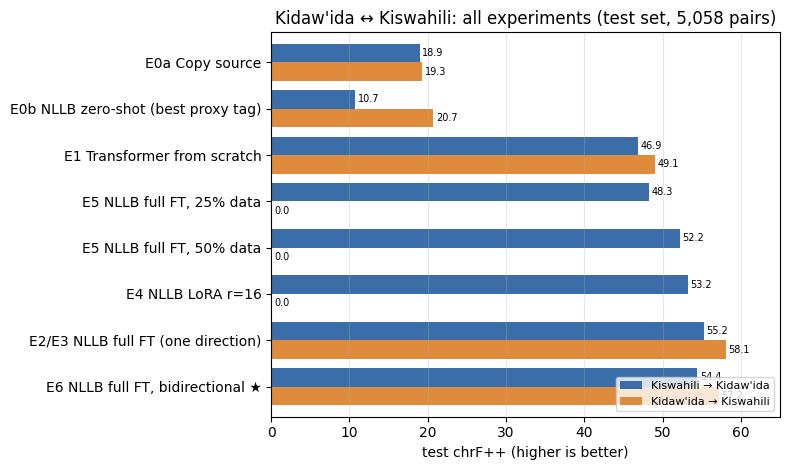

In [ ]:
plot_df = final_table.set_index('System')[['swa→dav chrF++', 'dav→swa chrF++']]
ax = plot_df.plot.barh(figsize=(8, 4.8), width=0.8, color=['#3b6ea8', '#e08a3c'])
for c in ax.containers:
    ax.bar_label(c, fmt='%.1f', fontsize=7, padding=2)
ax.invert_yaxis(); ax.set_xlabel('test chrF++ (higher is better)'); ax.set_ylabel('')
ax.set_title("Kidaw'ida ↔ Kiswahili: all experiments (test set, 5,058 pairs)")
ax.legend(['Kiswahili → Kidaw\'ida', 'Kidaw\'ida → Kiswahili'], loc='lower right', fontsize=8)
ax.set_xlim(0, max(65, plot_df.max().max() + 6)); ax.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/results_bar.png', dpi=150); plt.show()

## 4. Are the differences real? Paired bootstrap resampling

A difference of 1 chrF++ point could be luck: it depends on which sentences happen to be in the test set. **Paired bootstrap resampling** (Koehn, 2004) answers this: resample the 5,058 test sentences with replacement 1,000 times, score both systems on each resample, and count how often the "better" system loses. If that happens in fewer than 5% of resamples (p < 0.05), the difference is statistically significant. We use `sacrebleu`'s implementation, which also gives a 95% confidence interval for each score.

In [ ]:
COMPARISONS = [
    # (question, direction, baseline pred file, system pred file)
    ('Pretraining vs scratch',        'swa→dav', 'E1_transformer_beam4', 'E2_nllb_full'),
    ('Pretraining vs scratch',        'dav→swa', 'E1_transformer_beam4', 'E3_nllb_full'),
    ('Bidirectional vs one-direction', 'swa→dav', 'E2_nllb_full',         'E6_nllb_bidirectional'),
    ('Bidirectional vs one-direction', 'dav→swa', 'E3_nllb_full',         'E6_nllb_bidirectional'),
    ('LoRA vs full fine-tuning',      'swa→dav', 'E2_nllb_full',         'E4_nllb_lora'),
    ('50% vs 100% data',              'swa→dav', 'E5_nllb_full_p50',     'E2_nllb_full'),
    ('25% data NLLB vs 100% scratch', 'swa→dav', 'E1_transformer_beam4', 'E5_nllb_full_p25'),
]

sig_rows = []
for question, direction, base, sys_ in COMPARISONS:
    src, tgt = direction.split('→')
    b, s = load_pred(base, src, tgt), load_pred(sys_, src, tgt)
    if b is None or s is None:
        print('missing predictions for', question, direction); continue
    assert (b.ref == s.ref).all(), 'prediction files are not aligned'
    test = PairedTest([(base, b.hyp.tolist()), (sys_, s.hyp.tolist())],
                      {'chrF++': CHRF(word_order=2), 'BLEU': BLEU()},
                      references=[b.ref.tolist()], test_type='bs', n_samples=1000)
    _, scores = test()
    rb, rs = scores['chrF2++']          # sacrebleu names chrF++ "chrF2++"
    bb, bs = scores['BLEU']
    sig_rows.append({'Question': question, 'Direction': direction, 'Baseline': base, 'System': sys_,
                     'Baseline chrF++': f'{rb.score:.2f} ± {rb.ci:.2f}', 'System chrF++': f'{rs.score:.2f} ± {rs.ci:.2f}',
                     'Δ chrF++': round(rs.score - rb.score, 2), 'p (chrF++)': round(rs.p_value, 4),
                     'Δ BLEU': round(bs.score - bb.score, 2), 'p (BLEU)': round(bs.p_value, 4),
                     'Significant (p<0.05)': 'yes' if rs.p_value < 0.05 else 'no'})
sig = pd.DataFrame(sig_rows)
sig.to_csv(f'{RESULTS_DIR}/significance.csv', index=False)
summary['significance'] = sig.to_dict(orient='records')
sig

,Question,Direction,Baseline,System,Baseline chrF++,System chrF++,Δ chrF++,p (chrF++),Δ BLEU,p (BLEU),Significant (p<0.05)
0,Pretraining vs scratch,swa→dav,E1_transformer_beam4,E2_nllb_full,46.85 ± 0.65,55.25 ± 0.70,8.40,0.001,6.11,0.0010,yes
1,Pretraining vs scratch,dav→swa,E1_transformer_beam4,E3_nllb_full,49.06 ± 0.70,58.08 ± 0.72,9.02,0.001,10.43,0.0010,yes
2,Bidirectional vs one-direction,swa→dav,E2_nllb_full,E6_nllb_bidirectional,55.25 ± 0.70,54.39 ± 0.67,-0.86,0.001,-0.10,0.2727,yes
3,Bidirectional vs one-direction,dav→swa,E3_nllb_full,E6_nllb_bidirectional,58.08 ± 0.72,57.17 ± 0.69,-0.90,0.001,-0.55,0.0559,yes
4,LoRA vs full fine-tuning,swa→dav,E2_nllb_full,E4_nllb_lora,55.25 ± 0.70,53.22 ± 0.69,-2.03,0.001,-1.28,0.0010,yes
5,50% vs 100% data,swa→dav,E5_nllb_full_p50,E2_nllb_full,52.20 ± 0.66,55.25 ± 0.70,3.05,0.001,2.71,0.0010,yes
6,25% data NLLB vs 100% scratch,swa→dav,E1_transformer_beam4,E5_nllb_full_p25,46.85 ± 0.65,48.30 ± 0.66,1.44,0.001,-0.13,0.2777,yes


---
## Error analysis

From here on we focus on the **deployed model (E6)** and compare it with the **scratch Transformer (E1)** to see *where* pretraining helps.

In [ ]:
SYS = {'E1 scratch': 'E1_transformer_beam4', 'E6 NLLB': 'E6_nllb_bidirectional'}
DIRS = [('swa', 'dav'), ('dav', 'swa')]
preds = {(name, s, t): load_pred(f, s, t) for name, f in SYS.items() for s, t in DIRS}
assert all(v is not None for v in preds.values()), 'missing prediction files'
LANG = {'dav': "Kidaw'ida", 'swa': 'Kiswahili'}

def words(s):
    return re.findall(r"[\w']+", s.lower())

def corpus_chrf(df):
    return sacrebleu.corpus_chrf(df.hyp.tolist(), [df.ref.tolist()], word_order=2).score

## 5. Score by sentence length

Are long sentences harder? Test sentences are grouped by source length in words; each group is scored with corpus chrF++.

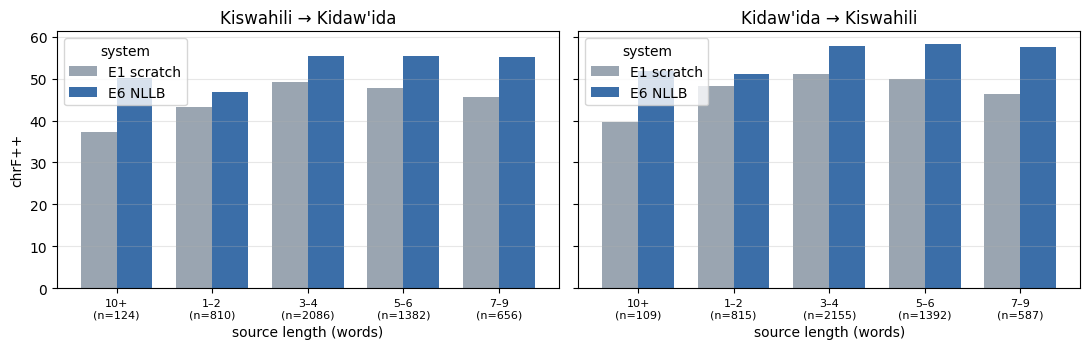

system            E1 scratch  E6 NLLB
direction length                     
dav→swa   10+          39.71    51.76
          1–2          48.25    51.09
          3–4          51.20    57.81
          5–6          49.98    58.38
          7–9          46.27    57.52
swa→dav   10+          37.15    50.06
          1–2          43.20    46.78
          3–4          49.14    55.30
          5–6          47.79    55.38
          7–9          45.57    55.18

In [ ]:
BINS, LABELS = [0, 2, 4, 6, 9, 100], ['1–2', '3–4', '5–6', '7–9', '10+']
len_rows = []
for (name, s, t), df in preds.items():
    d = df.copy()
    d['bucket'] = pd.cut(d.src.map(lambda x: len(x.split())), BINS, labels=LABELS)
    for b, g in d.groupby('bucket', observed=True):
        len_rows.append({'system': name, 'direction': f'{s}→{t}', 'length': b, 'n': len(g), 'chrF++': round(corpus_chrf(g), 2)})
len_tab = pd.DataFrame(len_rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (s, t) in zip(axes, DIRS):
    sub = len_tab[len_tab.direction == f'{s}→{t}'].pivot(index='length', columns='system', values='chrF++')
    sub.plot.bar(ax=ax, rot=0, width=0.75, color=['#9aa5b1', '#3b6ea8'])
    n = len_tab[(len_tab.direction == f'{s}→{t}') & (len_tab.system == 'E6 NLLB')].set_index('length').n
    ax.set_xticklabels([f'{l}\n(n={n.get(l, 0)})' for l in sub.index], fontsize=8)
    ax.set_title(f'{LANG[s]} → {LANG[t]}'); ax.set_xlabel('source length (words)'); ax.grid(axis='y', alpha=0.3)
axes[0].set_ylabel('chrF++')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/length_buckets.png', dpi=150); plt.show()
summary['length_buckets'] = len_tab.to_dict(orient='records')
len_tab.pivot_table(index=['direction', 'length'], columns='system', values='chrF++', observed=True)

## 6. Unseen (out-of-vocabulary) words

Notebook 01 showed that 17% of Kidaw'ida test words never appear in training. Two different problems:
- **Source OOV** — the input contains a word the model never saw. Can it still translate the sentence?
- **Reference OOV** — the correct translation contains a word that never appears in the training targets. A model that only learned from this data has no way to produce it.

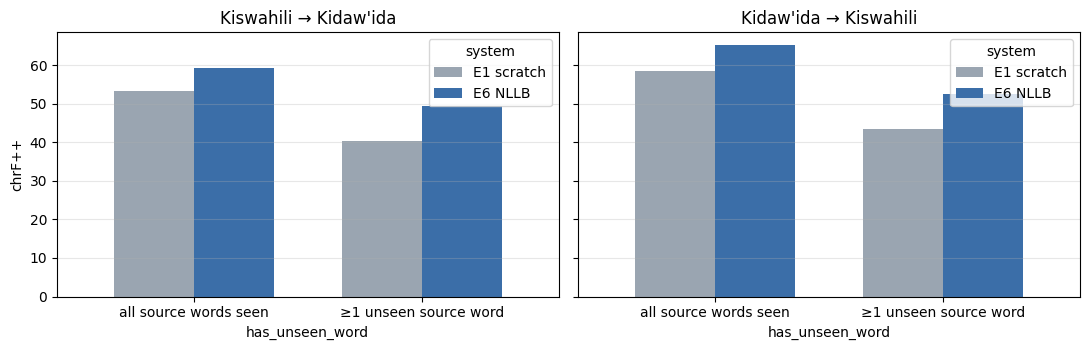

chrF++                  n        
system                              E1 scratch E6 NLLB E1 scratch E6 NLLB
direction side      has_unseen_word                                      
dav→swa   reference False                57.00   64.74     2756.0  2756.0
                    True                 41.02   49.53     2302.0  2302.0
          source    False                58.48   65.21     2102.0  2102.0
                    True                 43.41   52.37     2956.0  2956.0
swa→dav   reference False                56.07   63.12     2102.0  2102.0
                    True                 41.31   49.15     2956.0  2956.0
          source    False                53.16   59.19     2756.0  2756.0
                    True                 40.40   49.50     2302.0  2302.0

system                     E1 scratch  E6 NLLB  E6 − E1
direction has_unseen_word                              
dav→swa   False                 58.48    65.21     6.73
          True                  43.41    52.37     8.96
swa→dav   False                 53.16    59.19     6.03
          True                  40.40    49.50     9.10

In [ ]:
vocab = {lang: set(w for s in train_df[lang] for w in words(s)) for lang in ['dav', 'swa']}
oov_rows = []
for (name, s, t), df in preds.items():
    d = df.copy()
    d['src_oov'] = d.src.map(lambda x: any(w not in vocab[s] for w in words(x)))
    d['ref_oov'] = d.ref.map(lambda x: any(w not in vocab[t] for w in words(x)))
    for col, label in [('src_oov', 'source'), ('ref_oov', 'reference')]:
        for flag, g in d.groupby(col):
            oov_rows.append({'system': name, 'direction': f'{s}→{t}', 'side': label,
                             'has_unseen_word': bool(flag), 'n': len(g), 'chrF++': round(corpus_chrf(g), 2)})
oov_tab = pd.DataFrame(oov_rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (s, t) in zip(axes, DIRS):
    sub = oov_tab[(oov_tab.direction == f'{s}→{t}') & (oov_tab.side == 'source')]
    sub = sub.pivot(index='has_unseen_word', columns='system', values='chrF++')
    sub.index = sub.index.map({False: 'all source words seen', True: '≥1 unseen source word'})
    sub.plot.bar(ax=ax, rot=0, width=0.7, color=['#9aa5b1', '#3b6ea8'])
    ax.set_title(f'{LANG[s]} → {LANG[t]}'); ax.grid(axis='y', alpha=0.3)
axes[0].set_ylabel('chrF++')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/oov_effect.png', dpi=150); plt.show()

# Pretraining should help most where words are unseen: gap between E6 and E1 per group
gap = oov_tab[oov_tab.side == 'source'].pivot_table(index=['direction', 'has_unseen_word'], columns='system', values='chrF++')
gap['E6 − E1'] = gap['E6 NLLB'] - gap['E1 scratch']
summary['oov'] = oov_tab.to_dict(orient='records')
display(oov_tab.pivot_table(index=['direction', 'side', 'has_unseen_word'], columns='system', values=['n', 'chrF++']))
gap

## 7. Automatic error indicators

Each indicator is computed for every test sentence, then averaged (share of sentences, in %):

| Indicator | Definition | What it reveals |
|---|---|---|
| **Exact match** | output = reference (ignoring case/punctuation) | fully correct translations |
| **Source copying** | ≥1 output word copied from the source that is *not* in the reference | untranslated words leaking through, e.g. Swahili words left in a Kidaw'ida output |
| **Repetition** | the same word 3+ times in a row | a typical neural MT failure mode |
| **Too short / too long** | output length < 0.5× or > 2× the reference | dropped content / hallucinated content |
| **Apostrophe forms** | % of references with a `w'`-style apostrophe word, and how often the output has one too | Kidaw'ida orthography: the tokenizer splits `'` into its own piece |
| **Numbers kept** | among sources with digits, % of outputs containing the same digits | names/numbers are a known weakness of subword MT |

In [ ]:
norm = lambda s: ' '.join(words(s))
def indicators(df, src, tgt):
    out = []
    for x, r, h in zip(df.src, df.ref, df.hyp):
        sw, rw, hw = set(words(x)), set(words(r)), words(h)
        n_r = max(len(words(r)), 1)
        digits_src = re.findall(r'\d+', x)
        out.append({
            'exact_match': norm(h) == norm(r),
            'source_copying': any(w in sw and w not in rw for w in hw),
            'repetition': any(hw[i] == hw[i + 1] == hw[i + 2] for i in range(len(hw) - 2)),
            'too_short': len(hw) < 0.5 * n_r,
            'too_long': len(hw) > 2 * n_r,
            'ref_has_apostrophe': "'" in r,
            'hyp_has_apostrophe': "'" in h,
            'has_digits': bool(digits_src),
            'digits_kept': bool(digits_src) and all(d in h for d in digits_src),
        })
    return pd.DataFrame(out)

ind_rows = []
for (name, s, t), df in preds.items():
    ind = indicators(df, s, t)
    row = {'system': name, 'direction': f'{s}→{t}'}
    for c in ['exact_match', 'source_copying', 'repetition', 'too_short', 'too_long']:
        row[c + ' %'] = round(100 * ind[c].mean(), 1)
    apo = ind[ind.ref_has_apostrophe]
    row['refs with apostrophe %'] = round(100 * ind.ref_has_apostrophe.mean(), 1)
    row['…and output has one %'] = round(100 * apo.hyp_has_apostrophe.mean(), 1) if len(apo) else np.nan
    dig = ind[ind.has_digits]
    row['numbers kept %'] = round(100 * dig.digits_kept.mean(), 1) if len(dig) else np.nan
    row['n with numbers'] = len(dig)
    ind_rows.append(row)
ind_tab = pd.DataFrame(ind_rows)
ind_tab.to_csv(f'{RESULTS_DIR}/error_indicators.csv', index=False)
summary['error_indicators'] = ind_tab.to_dict(orient='records')
ind_tab.T

,0,1,2,3
system,E1 scratch,E1 scratch,E6 NLLB,E6 NLLB
direction,swa→dav,dav→swa,swa→dav,dav→swa
exact_match %,7.2,11.6,10.2,17.3
source_copying %,15.8,9.4,14.3,9.6
repetition %,0.4,0.2,0.0,0.0
too_short %,0.4,0.4,0.3,0.3
too_long %,0.2,0.2,0.3,0.3
refs with apostrophe %,33.9,0.9,33.9,0.9
…and output has one %,74.7,46.5,81.2,53.5
numbers kept %,20.0,0.0,60.0,100.0


In [ ]:
# Which source words get copied through most often by the deployed model? (top offenders)
for s, t in DIRS:
    df = preds[('E6 NLLB', s, t)]
    c = Counter(w for x, r, h in zip(df.src, df.ref, df.hyp)
                for w in set(words(h)) if w in set(words(x)) and w not in set(words(r)))
    print(f'{s}→{t} most copied words:', c.most_common(15))

swa→dav most copied words: [('na', 79), ('kwa', 75), ('ni', 63), ('ya', 39), ('kila', 18), ('wa', 14), ('kazi', 13), ('hata', 10), ('cha', 9), ('kesho', 9), ('nyumba', 8), ('tu', 7), ('pia', 7), ('bila', 6), ('yako', 6)]
dav→swa most copied words: [('na', 117), ('kwa', 47), ('ni', 31), ('wa', 15), ('ya', 15), ('hata', 12), ('cha', 9), ('nyumba', 5), ('sana', 5), ('mali', 4), ('kiriba', 3), ('mnavu', 3), ('wakati', 3), ('ndunda', 3), ('bidii', 3)]


## 8. Qualitative examples

- **Best / median / worst** E6 translations per direction (by sentence chrF++).
- **The same sentence through every system** (zero-shot NLLB → scratch Transformer → fine-tuned NLLB) — a good visual for the video.

In [ ]:
qual = []
for s, t in DIRS:
    df = preds[('E6 NLLB', s, t)].sort_values('chrF++').reset_index(drop=True)
    picks = {'worst': df.head(4), 'median': df.iloc[len(df) // 2 - 2: len(df) // 2 + 2], 'best': df.tail(4)}
    for kind, g in picks.items():
        for _, r in g.iterrows():
            qual.append({'direction': f'{s}→{t}', 'kind': kind, **r[['src', 'ref', 'hyp', 'chrF++']].to_dict()})
qual = pd.DataFrame(qual)
qual.to_csv(f'{RESULTS_DIR}/qualitative_examples.csv', index=False)
qual

,direction,kind,src,ref,hyp,chrF++
0,swa→dav,worst,huku,nokunu,aha,0.00
1,swa→dav,worst,Tegemeo,Isuwirio,Kutegemea,1.74
2,swa→dav,worst,imee,Ndeimuse,ghwachua,1.79
3,swa→dav,worst,changamoto,changamodo,wasi,2.27
4,swa→dav,median,Unaumwa na tumbo?,kwaw'elumwa ni kifu,Kwaw'ejighwa ni kifu?,52.38
5,swa→dav,median,Watu wote wanafaa kumtukuza Bwana,W'andu w'ose w'imtase Bwana.,W'andu w'ose w'efwana w'ikase Mlungu.,52.39
6,swa→dav,median,Watu wanatoka pahali popote,W'andu w'adafuma andu kokose,W'andu w'afuma andu kungi.,52.42
7,swa→dav,median,Mwanaume mtanashati huoga kila siku,Mndu waw'omi ughokie wadaogha kila ituku,Mundu wa mashati wadaogha kila ituku.,52.42
8,swa→dav,best,Hospitali zimejengwa kila mahali nchini.,Hospitali raaghilo kila andu isangenyi.,Hospitali raaghilo kila andu isangenyi.,100.00
9,swa→dav,best,Mtoto anatambaa,Mwana waw'eavua,Mwana waw'eavua,100.00


In [ ]:
ZS = {'swa→dav': 'E0b_nllb_zeroshot_swh-kik', 'dav→swa': 'E0b_nllb_zeroshot_swh-swh'}
side = []
for s, t in DIRS:
    zs = load_pred(ZS[f'{s}→{t}'], s, t)
    e1, e6 = preds[('E1 scratch', s, t)], preds[('E6 NLLB', s, t)]
    # sentences where E6 clearly beats E1 (pretraining helps) and a few random ones
    diff = (e6['chrF++'] - e1['chrF++'])
    idx = list(diff.sort_values(ascending=False).index[:3]) + list(e6.sample(3, random_state=SEED).index)
    for i in idx:
        side.append({'direction': f'{s}→{t}', 'source': e6.src[i], 'reference': e6.ref[i],
                     'E0b zero-shot': zs.hyp[i] if zs is not None else '', 'E1 scratch': e1.hyp[i],
                     'E6 fine-tuned': e6.hyp[i], 'E1 chrF++': e1['chrF++'][i], 'E6 chrF++': e6['chrF++'][i]})
side = pd.DataFrame(side)
side.to_csv(f'{RESULTS_DIR}/side_by_side_examples.csv', index=False)
side

,direction,source,reference,E0b zero-shot,E1 scratch,E6 fine-tuned,E1 chrF++,E6 chrF++
0,swa→dav,Somo letu limeisha,Ishomo jedu jasia,Wĩruti witũ nĩ ũhĩtũku,Soda yadisia,Ishomo jedu jasia,8.20,100.00
1,swa→dav,Thelathini,Mrongo idadu,Mĩaka mĩrongo ĩtatũ,Nawefunya ilaghiro,Mrongo idadu,8.29,100.00
2,swa→dav,Mjaze,Mchure,Ĩiyũre,Mkacha,Mchure,10.00,100.00
3,swa→dav,Mawingu yanapita.,Mawingu ghaweida.,Mairũ nĩ marathiĩ.,Maw'ingu ghaweida.,Makungughu ghaweida.,76.64,63.99
4,swa→dav,Chai ni mmea muhimu barani Afrika.,Chai ni mmea ghwa mana sana Afrika.,Chaa nĩ mũtĩ wa bata mũno thĩinĩ wa Afrika.,Chai chabuka maana maana maana Afrika.,Chai ni kimu cha mana cha Africa.,38.28,35.15
5,swa→dav,Msichana wangu alikuwa hasikii vizuri.,Mwai wapo ndousindee sikira nicha.,Mũirĩtu wakwa ndaiguaga wega.,Mwai wapo osikira nicha.,Mwai wapo osindasikira nicha.,57.63,60.39
6,dav→swa,Naighu,juu,Naighu,nalale,juu,0.00,100.00
7,dav→swa,Vichuku,ukoo,Dhana,Vijamii,ukoo,0.00,100.00
8,dav→swa,Nawahoresha,Napumzika,Ninaboresha,Ninapona,Napumzika,9.95,100.00
9,dav→swa,Mawingu ghaweida.,Mawingu yanapita.,Mawingu yanatokea.,Mawingu yanapita.,Mawingu yanapita.,100.00,100.00


## 9. Manual annotation sheet (dav→swa)

Automatic metrics can't tell *why* a translation is wrong. We sample **50 random dav→swa outputs** from E6 — you can judge these because the output is Swahili.

1. Open `results/manual_annotation.csv` in Google Sheets (right-click on Drive → Open with → Google Sheets).
2. For each row fill in **adequacy** (1 = meaning lost … 4 = meaning fully preserved), **fluency** (1 = broken … 4 = natural Swahili) and an **error** category:
   `none`, `wrong_word` (wrong lexical choice), `missing` (content dropped), `added` (content invented), `grammar` (agreement / tense / noun class), `untranslated` (Kidaw'ida left in output), `reference_error` (the reference itself is wrong).
3. Save it as CSV in the same place (File → Download → CSV, upload to `results/`, same name) and re-run the next cell.

Reporting even 50 human judgements makes the error analysis much stronger than metrics alone. (`reference_error` matters: community-collected data contains some mistranslated references.)

In [ ]:
ANN = f'{RESULTS_DIR}/manual_annotation.csv'
if not os.path.exists(ANN):
    e6 = preds[('E6 NLLB', 'dav', 'swa')]
    sheet = e6.sample(50, random_state=SEED)[['src', 'ref', 'hyp', 'chrF++']].reset_index().rename(columns={'index': 'test_row'})
    sheet['adequacy_1to4'] = ''; sheet['fluency_1to4'] = ''; sheet['error'] = ''; sheet['comment'] = ''
    sheet.to_csv(ANN, index=False)
    print('Created', ANN, '- fill it in, then re-run this cell.')
else:
    ann = read(ANN)
    done = ann[ann.adequacy_1to4.astype(str).str.strip() != '']
    print(f'{len(done)}/{len(ann)} rows annotated')
    if len(done):
        a = pd.to_numeric(done.adequacy_1to4, errors='coerce'); f = pd.to_numeric(done.fluency_1to4, errors='coerce')
        print(f'mean adequacy {a.mean():.2f}/4 | mean fluency {f.mean():.2f}/4 | '
              f'corr(adequacy, chrF++) = {np.corrcoef(a.fillna(a.mean()), done["chrF++"])[0, 1]:.2f}')
        errs = done.error.str.strip().str.lower().replace('', 'unlabelled').value_counts()
        display(errs.to_frame('count'))
        summary['manual_annotation'] = {'n': int(len(done)), 'adequacy': round(float(a.mean()), 2),
                                        'fluency': round(float(f.mean()), 2), 'errors': errs.to_dict()}
        errs.plot.barh(figsize=(5, 3), title='Manual error categories (E6, dav→swa)'); plt.gca().invert_yaxis()
        plt.tight_layout(); plt.savefig(f'{FIG_DIR}/manual_errors.png', dpi=150); plt.show()

Created /content/drive/MyDrive/kidawida-mt/results/manual_annotation.csv - fill it in, then re-run this cell.


## 10. Stress tests and round-trip consistency (deployed model)

This loads the final E6 model saved by notebook 03 (≈1.2 GB) and probes behaviour the test set doesn't cover:
- **Stress tests:** numbers, names, a long sentence, a question, an out-of-domain (formal / technical) sentence, a greeting. Edit `PROBES` freely.
- **Round-trip:** translate 300 test sentences swa→dav→swa and score the result against the original Swahili. A good round-trip isn't proof of a good translation, but a bad one exposes information lost along the way.

Use a GPU runtime if you can; on CPU this section takes ~10–15 minutes.

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

device = 'cuda' if torch.cuda.is_available() else 'cpu'
cfg = json.load(open(f'{FINAL_DIR}/mt_config.json'))
tok = AutoTokenizer.from_pretrained(FINAL_DIR)
model = AutoModelForSeq2SeqLM.from_pretrained(FINAL_DIR, torch_dtype=torch.float16 if device == 'cuda' else torch.float32).to(device).eval()
LANG_CODE, MAX_LEN = cfg['lang_codes'], cfg['max_len']
code_id = lambda lang: tok.convert_tokens_to_ids(LANG_CODE[lang])
print('Loaded', FINAL_DIR, 'on', device, '| dav tag id', code_id('dav'))

@torch.no_grad()
def translate(sentences, src, tgt, beams=4, bs=32):
    """Same input format as training: [src_tag] subwords </s>; decoder forced to start with tgt_tag."""
    sentences = list(sentences); out = [None] * len(sentences)
    order = np.argsort([len(s) for s in sentences])
    for i in range(0, len(order), bs):
        idx = order[i:i + bs]
        ids = tok([sentences[j] for j in idx], add_special_tokens=False)['input_ids']
        ids = [[code_id(src)] + x[:MAX_LEN - 2] + [tok.eos_token_id] for x in ids]
        L = max(map(len, ids))
        inp = torch.tensor([x + [tok.pad_token_id] * (L - len(x)) for x in ids], device=device)
        gen = model.generate(input_ids=inp, attention_mask=(inp != tok.pad_token_id).long(),
                             forced_bos_token_id=code_id(tgt), num_beams=beams, max_new_tokens=MAX_LEN)
        for j, t in zip(idx, tok.batch_decode(gen, skip_special_tokens=True)):
            out[j] = t.strip()
    return out

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/509 [00:00<?, ?it/s]

Loaded /content/drive/MyDrive/kidawida-mt/models/nllb_dav_swa_final on cuda | dav tag id 256204


In [ ]:
PROBES = [  # (category, Kiswahili input)
    ('number',        'Nina watoto watatu na ng\'ombe 25.'),
    ('number',        'Mkutano utaanza saa nne asubuhi tarehe 12.'),
    ('name/place',    'Mwashighadi anaishi Wundanyi karibu na Voi.'),
    ('name/place',    'Rais alitembelea Mombasa jana.'),
    ('question',      'Unaenda wapi kesho asubuhi?'),
    ('greeting',      'Habari za asubuhi, rafiki yangu.'),
    ('long',          'Tukiangalia hali ya hewa ya mwaka huu, wakulima wengi wa Taita wanahofia kwamba mvua haitatosha kwa mahindi na maharagwe yao.'),
    ('out-of-domain', 'Kompyuta hii inahitaji programu mpya ili kuunganishwa na mtandao.'),
    ('out-of-domain', 'Daktari alisema dawa hii inapaswa kunywewa mara tatu kwa siku baada ya chakula.'),
    ('negation',      'Sitaki chakula sasa hivi.'),
]
dav = translate([p for _, p in PROBES], 'swa', 'dav')
back = translate(dav, 'dav', 'swa')
stress = pd.DataFrame({'category': [c for c, _ in PROBES], 'kiswahili_input': [p for _, p in PROBES],
                       'kidawida_output': dav, 'back_to_kiswahili': back})
stress['roundtrip_chrF++'] = [round(sacrebleu.sentence_chrf(b, [p], word_order=2).score, 1) for b, (_, p) in zip(back, PROBES)]
stress.to_csv(f'{RESULTS_DIR}/stress_tests.csv', index=False)
stress

[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


,category,kiswahili_input,kidawida_output,back_to_kiswahili,roundtrip_chrF++
0,number,Nina watoto watatu na ng'ombe 25.,Neka na w'ana w'adadu na ng'ombe 25.,Nina watoto watatu na ng'ombe 25.,100.0
1,number,Mkutano utaanza saa nne asubuhi tarehe 12.,Mkutano ghwazoya saa inya ra luma lwa ituku jha ikumi na iw'i.,Mkutano utaanza saa nne jioni siku ya Disemba.,54.0
2,name/place,Mwashighadi anaishi Wundanyi karibu na Voi.,Mwashghadi wadakaia Wundanyi kavui na Voi.,Mwashgadi huwa Wundanyi karibu na Voi.,63.6
3,name/place,Rais alitembelea Mombasa jana.,Mbaa wa isanga oreendieghe Mombasa ikwau.,Rais alisafiri kwenda Mombasa jana.,60.0
4,question,Unaenda wapi kesho asubuhi?,Kwaw'eenda hao kesho luma lwa kesho?,Unaenda wapi kesho asubuhi?,100.0
5,greeting,"Habari za asubuhi, rafiki yangu.","Habari ra luma lwa kesho, mghenyu wapo.","Habari za kesho, rafiki yangu.",67.3
6,long,"Tukiangalia hali ya hewa ya mwaka huu, wakulima wengi wa Taita wanahofia kwamba mvua h...","Dikazighana hali ya mbeo ya ughu mwaka, w'akulima w'engi w'a Daw'ida w'aobua angu vua ...","Tukiangalia hali ya baridi ya mwaka huu, wakulima wengi wa Taita wanaogopa kuwa mvua h...",69.3
7,out-of-domain,Kompyuta hii inahitaji programu mpya ili kuunganishwa na mtandao.,Ihii kompiuta yekunda programu mbishi eri ifwane na mtandao.,Kompyuta hii inahitaji programu mpya ili kuendana na mtandao.,81.8
8,out-of-domain,Daktari alisema dawa hii inapaswa kunywewa mara tatu kwa siku baada ya chakula.,Mrighiti waghorie ughu w'ughanga ni suti ghunweko mando adadu kwa ituku baada ya vindo.,Daktari alisema dawa hii lazima itolewe mara tatu kwa siku baada ya chakula.,75.6
9,negation,Sitaki chakula sasa hivi.,Sikunde vindo itanaa.,Sitaki chakula saa hizi,61.6


In [ ]:
N_RT = 300
sample = test_df.sample(N_RT, random_state=SEED)
dav_out = translate(sample.swa, 'swa', 'dav')
swa_back = translate(dav_out, 'dav', 'swa')
rt = pd.DataFrame({'swa_original': sample.swa.values, 'dav_reference': sample.dav.values,
                   'dav_model': dav_out, 'swa_roundtrip': swa_back})
rt['roundtrip_chrF++'] = [round(sacrebleu.sentence_chrf(b, [o], word_order=2).score, 1) for b, o in zip(rt.swa_roundtrip, rt.swa_original)]
rt.to_csv(f'{RESULTS_DIR}/roundtrip.csv', index=False)
rt_score = sacrebleu.corpus_chrf(rt.swa_roundtrip.tolist(), [rt.swa_original.tolist()], word_order=2).score
fwd_score = sacrebleu.corpus_chrf(rt.dav_model.tolist(), [rt.dav_reference.tolist()], word_order=2).score
summary['roundtrip'] = {'n': N_RT, 'swa→dav→swa chrF++': round(rt_score, 2), 'swa→dav chrF++ on same sample': round(fwd_score, 2)}
print(summary['roundtrip'])
rt.sort_values('roundtrip_chrF++').head(8)

[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

{'n': 300, 'swa→dav→swa chrF++': 66.64, 'swa→dav chrF++ on same sample': 53.49}


,swa_original,dav_reference,dav_model,swa_roundtrip,roundtrip_chrF++
137,Kombamwiko,Nyeche,kodemmbonya,umemfanya,4.4
253,huku,nokunu,aha,hapa,5.0
117,chukieni maovu,Menyeni mawiwi,Venyi maw'iw'i,Venyi viwili,6.0
54,Nitayaharibu pia madhabahu,Nicharitotesha madhabahu,Nichaibwagha na madhabahu.,Nitapiga magoti na mawe.,12.1
288,Amewatenganisha wasipigane,W'aw'itanya wiselo,Waw'itanya w'isekebulana.,Wanafanya tofauti bila kupigana.,13.1
15,akaibariki,Ukavirasimis,Ukairasimia,Akiwa anajiringa,13.2
34,Ana kucha ndefu,Oka na lwakule lulacha,Oka na chwakule ndacha.,Ako na kibuyu kirefu,13.3
244,Ana kucha ndefu,Oka na chwakule ndacha,Oka na chwakule ndacha.,Ako na kibuyu kirefu,13.3


## 11. Save the summary

In [ ]:
def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, list): return [clean(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return None if np.isnan(o) else float(o)
    if isinstance(o, float) and math.isnan(o): return None
    return o
with open(f'{RESULTS_DIR}/analysis_summary.json', 'w') as f:
    json.dump(clean(summary), f, indent=2, ensure_ascii=False)
print('Saved', f'{RESULTS_DIR}/analysis_summary.json')
print('Figures:', sorted(os.listdir(FIG_DIR)))

Saved /content/drive/MyDrive/kidawida-mt/results/analysis_summary.json
Figures: ['e1_training_curves.png', 'e5_learning_curve.png', 'length_buckets.png', 'length_scatter.png', 'nllb_val_curves.png', 'oov_effect.png', 'results_bar.png', 'sentence_length_hist.png']
